Models:

1. model_1: dataSGMM.context5000.feat100.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead8.nlayer6.ndevice1.numclusters100

2. model_2: dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead8.nlayer6.ndevice1.numclusters70

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import pickle
import torch

In [2]:
model_0_dir = "../results/adbench/(109datasets)_dataSGMM.context5000.feat100.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead8.nlayer6.ndevice1.numclusters100/train_seed=0.transform=quantile.feat_truncation=subsampling"

model_1_dir = "../results/adbench/dataSGMM.context5000.feat100.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead8.nlayer6.ndevice1.numclusters100/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_1_dir_loss = "../ckpt/dataSGMM.context5000.feat100.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead8.nlayer6.ndevice1.numclusters100/seed0/train_val_loss.pickle"


model_2_dir = "../results/adbench/dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead8.nlayer6.ndevice1.numclusters70/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_2_dir_loss = "../ckpt/dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead8.nlayer6.ndevice1.numclusters70/seed0/train_val_loss.pickle"

## 1. model_1

In [3]:
model_1_aucroc_scores = []
model_1_aucpr_scores = []
model_1_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_1_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_1_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_1_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_1_f1_scores.append(f1)

# compute average scores of all datasets
model_1_avg_aucroc = sum(model_1_aucroc_scores) / len(model_1_aucroc_scores)
model_1_avg_aucpr = sum(model_1_aucpr_scores) / len(model_1_aucpr_scores)
model_1_avg_f1 = sum(model_1_f1_scores) / len(model_1_f1_scores)

print(f"number of datasets: {len(model_1_aucroc_scores)}")
print(f"Average aucroc: {model_1_avg_aucroc}")
print(f"Average aucpr: {model_1_avg_aucpr}")
print(f"Average f1: {model_1_avg_f1}")

number of datasets: 121
Average aucroc: 0.7695414609453703
Average aucpr: 0.46190345098262275
Average f1: 0.4655173833092233


### model_1_loss

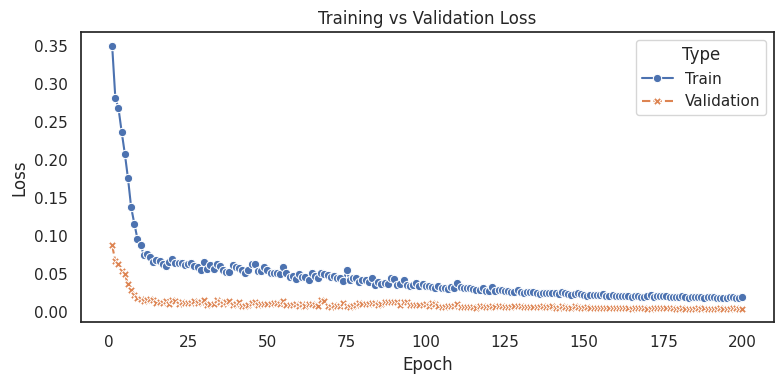

In [4]:
# load data
with open(model_1_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]

epochs = list(range(1, len(train_loss)+1))

# convert to dataframe (seaborn prefers tidy format)
df = pd.DataFrame({
    "Epoch": epochs + epochs,
    "Loss": train_loss + val_loss,
    "Type": ["Train"]*len(train_loss) + ["Validation"]*len(val_loss)
})

# seaborn style
sns.set_theme(style="white")  # darkgrid

plt.figure(figsize=(8,4))

ax = sns.lineplot(
    data=df,
    x="Epoch",
    y="Loss",
    hue="Type",
    style="Type",
    markers=True,
    dashes=True
)

# Force integer ticks
#ax.xaxis.set_major_locator(MaxNLocator(len(epochs), integer=True))

plt.title("Training vs Validation Loss")
plt.tight_layout()

plt.show()

Train loss: [0.3506691879630089, 0.28229433740675447, 0.2681390174776316, 0.2373293498158455, 0.20856257873028516, 0.17613574336469173, 0.1379274076670408, 0.116582972407341, 0.09635428189113736, 0.08856327877752483, 0.07528094684518874, 0.07599638746678829, 0.07285922103561461, 0.06568036985211075, 0.06871005075238645, 0.06788768706284463, 0.06313772293366492, 0.06045594555325806, 0.0658310808390379, 0.07004014401137829, 0.06479122725874185, 0.06447939207404851, 0.06475011309236288, 0.06218566875532269, 0.06340289156883955, 0.06448150900937617, 0.060699684937018904, 0.05887164136953652, 0.05543290917295963, 0.06599199640937149, 0.0564711479190737, 0.06260227252170443, 0.05714450741373003, 0.06294520783983171, 0.06122286997362971, 0.05606703854724765, 0.05350816399184987, 0.05234110467787832, 0.06174297113530338, 0.05991118448507041, 0.05813866946939379, 0.05529224788071588, 0.05184370169392787, 0.05553617083653808, 0.0634761082418263, 0.06307372794300317, 0.053744259538128974, 0.05403

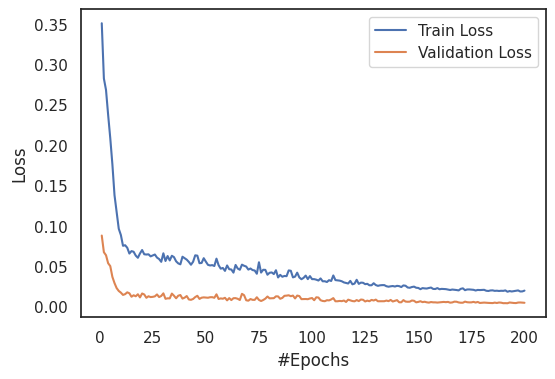

In [5]:
# load pickel
with open(model_1_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
train_time = data['train_time']

print("Train loss:", train_loss)
print("Val loss:", val_loss)
print("Train time", train_time)

# plot
epochs = range(1, len(train_loss) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")

plt.xlabel("#Epochs")
plt.ylabel("Loss")
#plt.title("Training vs Validation Loss")
#plt.legend(["Train Loss","Validation Loss", 'Train time = 140291.99s'])
plt.legend()
#plt.grid(True)

plt.show()

## 2. model_2


In [6]:
model_2_aucroc_scores = []
model_2_aucpr_scores = []
model_2_f1_scores = []
datasets_name = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_2_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_2_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_2_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_2_f1_scores.append(f1)

# compute average scores of all datasets
model_2_avg_aucroc = sum(model_2_aucroc_scores) / len(model_2_aucroc_scores)
model_2_avg_aucpr = sum(model_2_aucpr_scores) / len(model_2_aucpr_scores)
model_2_avg_f1 = sum(model_2_f1_scores) / len(model_2_f1_scores)

print(f"number of datasets: {len(model_2_aucroc_scores)}")
print(f"Average aucroc: {model_2_avg_aucroc}")
print(f"Average aucpr: {model_2_avg_aucpr}")
print(f"Average f1: {model_2_avg_f1}")

number of datasets: 121
Average aucroc: 0.6842635004196573
Average aucpr: 0.3589561584931166
Average f1: 0.3486122486993448


Train loss: [0.34890473663806915, 0.29053806187212466, 0.2697973486185074, 0.23107788780331612, 0.17341306392103434, 0.1347676796875894, 0.10715611576661467, 0.09473724810406565, 0.08145542954653502, 0.07833013698272408, 0.07760017281025648, 0.07322077572718262, 0.07164848037716001, 0.06738724637404084, 0.0672598380879499, 0.06664727281406521, 0.06792389164492488, 0.0650327115172986, 0.06823340077884495, 0.06287776936404407, 0.06503657408431172, 0.06449824846163392, 0.06017062932997942, 0.06772359412163496, 0.06410359123907983, 0.06983696138486266, 0.06780782590433955, 0.06555896126106381, 0.059878641854971645, 0.06435559947602451, 0.05559877680055797, 0.06531455366313457, 0.05822878855047747, 0.0584360976787284, 0.06062561413366348, 0.05639726330246776, 0.05392000669427216, 0.05994651223625988, 0.05748993606120348, 0.05837752922344953, 0.0649190880190581, 0.05623572917189449, 0.052371186215197665, 0.053496428347658366, 0.07947220679462771, 0.06524661473510787, 0.05744657167512923, 0.0

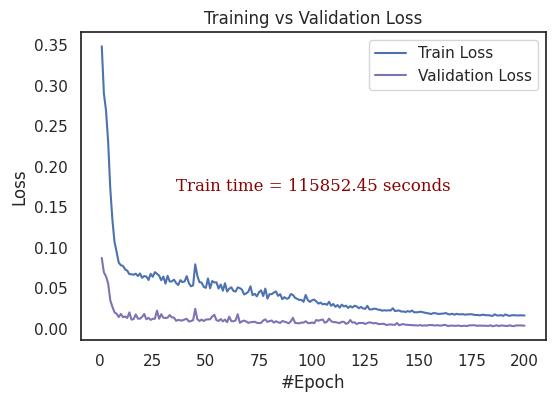

In [13]:
# load pickel
with open(model_2_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
train_time = data['train_time']

print("Train loss:", train_loss)
print("Val loss:", val_loss)
print("Train time", train_time)
font = {'family': 'serif',
        'color':  'darkred',
        'weight': 'normal',
        'size': 12,
        }
# plot
epochs = range(1, len(train_loss) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss", color='m')
plt.text(
    0.5, 0.5,
    r'Train time = 115852.45 seconds',
    fontdict=font,
    ha='center', va='center',
    transform=plt.gca().transAxes
)

plt.xlabel("#Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
#plt.grid(True)

plt.show()